# Edge Detection Techniques

This notebook explores first-order and second-order edge detection on a grayscale image:

- Sobel operator
- Prewitt operator
- Laplacian operator
- Laplacian of Gaussian (LoG)

The workflow follows the original exercise: add Gaussian noise, calculate edge responses, threshold gradient magnitudes, and detect zero crossings for second-order methods.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## 1. Load the image and add Gaussian noise

A Gaussian noise sample with mean 0 and standard deviation 20 is added to the grayscale image. Floating-point arithmetic is used to avoid unsigned-integer overflow.

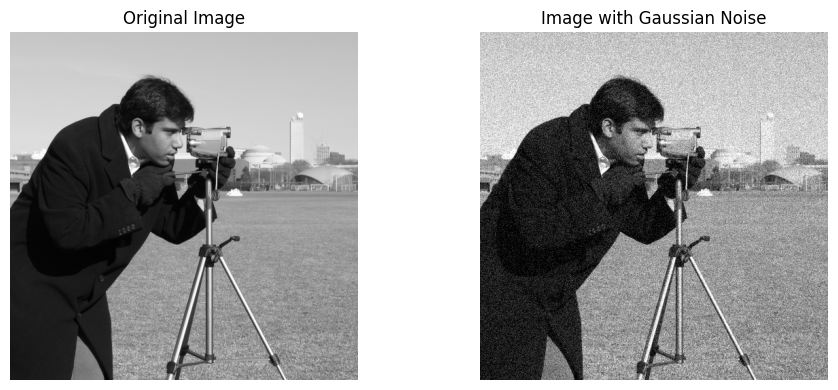

In [2]:
image = data.camera().astype(np.float32)

rng = np.random.default_rng(42)
noise = rng.normal(0, 20, image.shape)
noisy_image = np.clip(image + noise, 0, 255)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[1].imshow(noisy_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Image with Gaussian Noise")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Define a convolution function

The convolution function pads the image at its borders and returns a floating-point response. Keeping signed values is important for derivative kernels because negative responses carry edge-direction information.

In [3]:
def convolve(image, kernel):
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image and kernel must be 2D arrays.")
    if kernel.shape[0] % 2 == 0 or kernel.shape[1] % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")

    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    output = np.zeros_like(image, dtype=np.float32)

    # Flip the kernel to perform mathematical convolution.
    flipped_kernel = np.flip(kernel, axis=(0, 1))
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i + kh, j:j + kw]
            output[i, j] = np.sum(region * flipped_kernel)

    return output

## 3. Sobel edge detection

Sobel uses two 3×3 derivative kernels to estimate horizontal and vertical intensity changes. The gradient magnitude combines both responses.

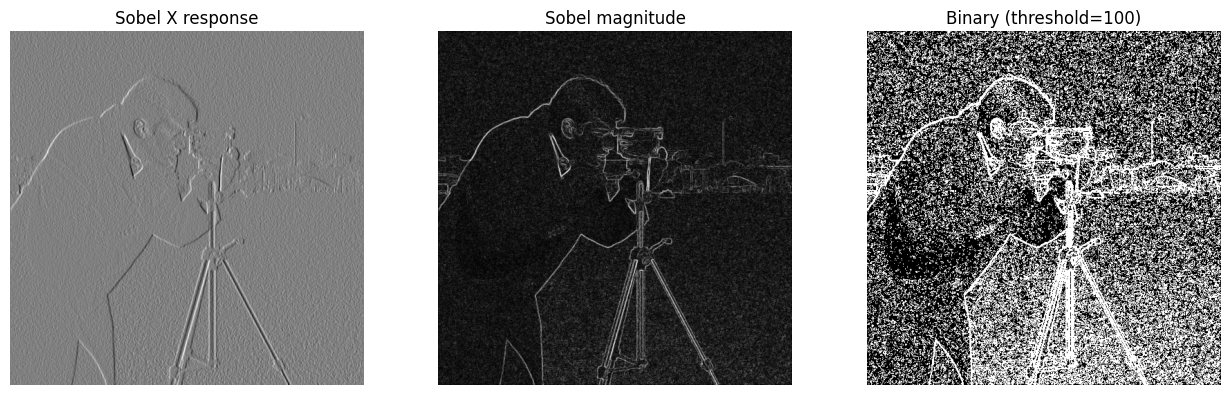

In [4]:
sobel_gx = np.array([[-1, 0, 1],
                      [-2, 0, 2],
                      [-1, 0, 1]], dtype=np.float32)
sobel_gy = np.array([[-1, -2, -1],
                      [0, 0, 0],
                      [1, 2, 1]], dtype=np.float32)

sobel_x = convolve(noisy_image, sobel_gx)
sobel_y = convolve(noisy_image, sobel_gy)
sobel_magnitude = np.hypot(sobel_x, sobel_y)

sobel_threshold = 100
sobel_binary = sobel_magnitude > sobel_threshold

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, result, title in zip(
    axes,
    [sobel_x, sobel_magnitude, sobel_binary],
    ["Sobel X response", "Sobel magnitude", f"Binary (threshold={sobel_threshold})"]
):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Prewitt edge detection

Prewitt also estimates horizontal and vertical gradients, using uniform weights in its 3×3 derivative kernels.

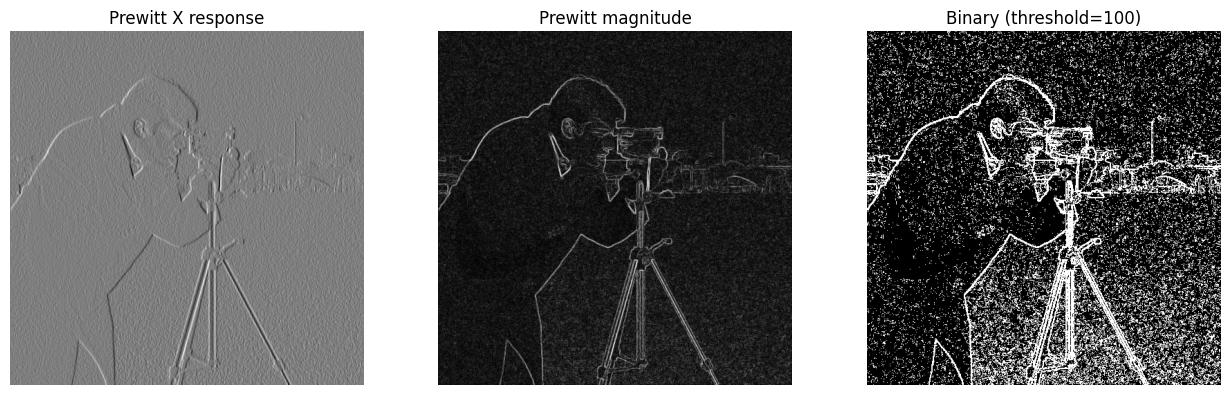

In [5]:
prewitt_gx = np.array([[-1, 0, 1],
                        [-1, 0, 1],
                        [-1, 0, 1]], dtype=np.float32)
prewitt_gy = np.array([[-1, -1, -1],
                        [0, 0, 0],
                        [1, 1, 1]], dtype=np.float32)

prewitt_x = convolve(noisy_image, prewitt_gx)
prewitt_y = convolve(noisy_image, prewitt_gy)
prewitt_magnitude = np.hypot(prewitt_x, prewitt_y)

prewitt_threshold = 100
prewitt_binary = prewitt_magnitude > prewitt_threshold

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, result, title in zip(
    axes,
    [prewitt_x, prewitt_magnitude, prewitt_binary],
    ["Prewitt X response", "Prewitt magnitude", f"Binary (threshold={prewitt_threshold})"]
):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Laplacian edge detection

The Laplacian is a second-order derivative operator. Its response contains positive and negative values. Zero crossings indicate locations where the response changes sign.

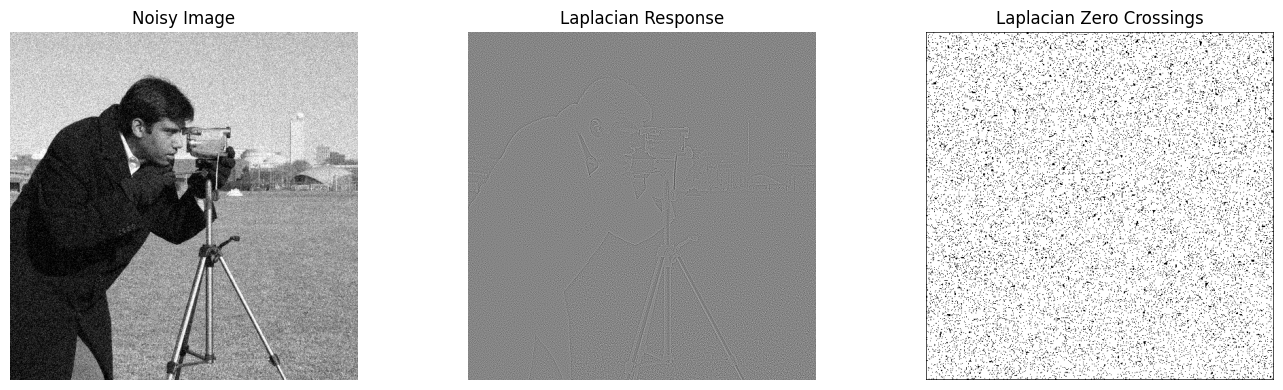

In [10]:
# Laplacian Edge Detection

laplacian_kernel = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

laplacian = convolve(noisy_image, laplacian_kernel)


# Zero Crossing Detection
def zero_crossing(response):
    response = np.asarray(response, dtype=np.float32)

    h, w = response.shape
    result = np.zeros((h, w), dtype=np.uint8)

    for i in range(1, h - 1):
        for j in range(1, w - 1):

            neighbors = [
                (response[i-1, j-1], response[i+1, j+1]),  # Diagonal
                (response[i-1, j+1], response[i+1, j-1]),  # Diagonal
                (response[i-1, j],   response[i+1, j]),    # Vertical
                (response[i, j-1],   response[i, j+1])     # Horizontal
            ]

            for p1, p2 in neighbors:
                if p1 * p2 < 0:
                    result[i, j] = 255
                    break

    return result


# Apply Zero Crossing
laplacian_edges = zero_crossing(laplacian)


# Display Results
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(noisy_image, cmap="gray")
axes[0].set_title("Noisy Image")

axes[1].imshow(laplacian, cmap="gray")
axes[1].set_title("Laplacian Response")

axes[2].imshow(laplacian_edges, cmap="gray")
axes[2].set_title("Laplacian Zero Crossings")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Laplacian of Gaussian (LoG)

LoG first smooths the image with a Gaussian kernel to reduce noise, then applies the Laplacian and detects zero crossings.

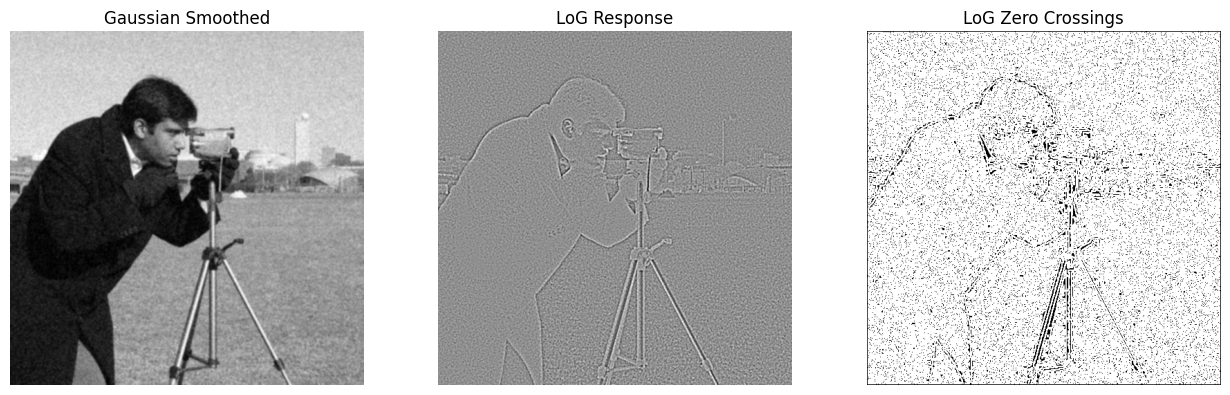

In [12]:
def gaussian_kernel(size=5, sigma=1.0):
    if size < 3 or size % 2 == 0:
        raise ValueError("size must be an odd integer >= 3")
    if sigma <= 0:
        raise ValueError("sigma must be positive")

    coordinates = np.arange(-(size // 2), size // 2 + 1, dtype=np.float32)
    xx, yy = np.meshgrid(coordinates, coordinates)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()

gaussian = gaussian_kernel(size=5, sigma=1.0)
smoothed = convolve(noisy_image, gaussian)
log_response = convolve(smoothed, laplacian_kernel)
log_edges = zero_crossing(log_response)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, result, title in zip(
    axes,
    [smoothed, log_response, log_edges],
    ["Gaussian Smoothed", "LoG Response", "LoG Zero Crossings"]
):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Compare the edge detectors

The following figure compares the binary Sobel and Prewitt maps with the zero-crossing maps from Laplacian and LoG.

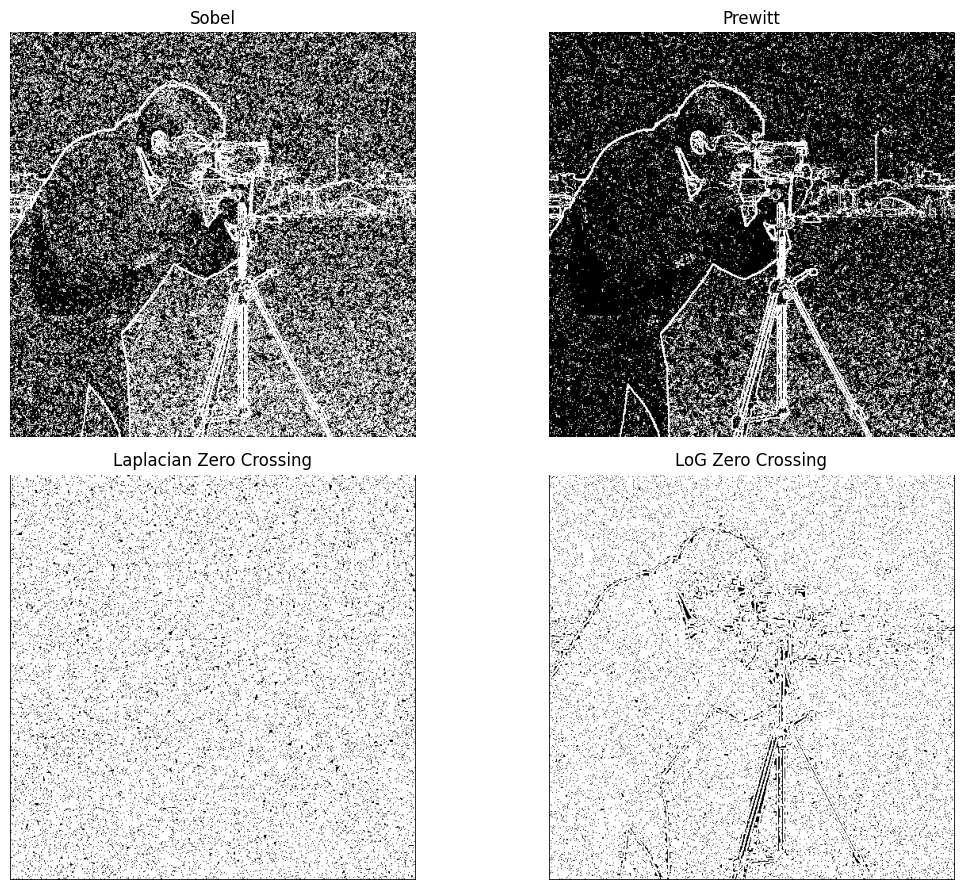

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
comparisons = [
    (sobel_binary, "Sobel"),
    (prewitt_binary, "Prewitt"),
    (laplacian_edges, "Laplacian Zero Crossing"),
    (log_edges, "LoG Zero Crossing")
]
for ax, (result, title) in zip(axes.flat, comparisons):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Key observations

- Sobel and Prewitt estimate first-order gradients in two directions; their magnitude maps highlight strong intensity changes.
- Laplacian uses a second-order derivative and identifies edges through sign changes (zero crossings).
- LoG smooths the image before applying the Laplacian, which can reduce sensitivity to noise.
- Binary edge maps depend on the selected threshold. Adjust the thresholds to observe how edge density changes.
- The custom convolution is intentionally implemented with loops for learning purposes; optimized library implementations are faster for large images.